# Análise exploratória: produção mensal de veículos no Brasil (1993-2022)

**Projeto Prático G2 - Linguagens de Programação (2026.2), Bacharelado em Sistemas de Informação**  
**Autores:** Marcelo Bernardes e Lucas Queiroz  
**Fonte:** ANFAVEA via Banco Central do Brasil (SGS 1373), republicada no Kaggle.

Este notebook é o espaço de exploração e validação. Toda a lógica reutilizável está em `src/etl.py` e `src/analise.py`; aqui apenas a executamos e inspecionamos os resultados que respondem às perguntas de pesquisa:

- **RQ1.** Como a produção evoluiu entre 1993 e 2022 e quais ciclos de expansão e retração aparecem?
- **RQ2.** Existe um padrão sazonal sistemático? Ele se manteve estável ao longo das décadas?
- **RQ3.** Qual foi a profundidade e a duração dos grandes choques, e quais meses são outliers?

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt

from src import etl, analise

%matplotlib inline
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
analise._estilo()

## 1. Ingestão e qualidade do dado bruto

O arquivo bruto usa `;` como separador, datas `dd/mm/aaaa` e todos os campos entre aspas. Lemos tudo como texto para que nenhuma conversão aconteça de forma implícita.

In [2]:
bruto, meta = etl.extract()
print(meta)
bruto.head()

{'arquivo_bruto': 'bcdata.sgs.1373.csv', 'codificacao': 'utf-8-sig', 'separador': ';', 'linhas_brutas': 359}


,data,valor
0,01/01/1993,66168
1,01/02/1993,73042
2,01/03/1993,98691
3,01/04/1993,88839
4,01/05/1993,101055


In [3]:
df, qualidade = etl.transform(bruto)
qualidade

{'datas_invalidas': 0,
 'valores_invalidos': 0,
 'valores_negativos': 0,
 'duplicatas_removidas': 0,
 'meses_ausentes': 0,
 'linhas_finais': 359,
 'periodo': ['1993-01', '2022-11'],
 'outliers_sinalizados': 16}

Não há datas inválidas, valores não numéricos, duplicatas nem meses ausentes: a série tem 359 meses contíguos. Por isso nenhuma imputação foi necessária.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 359 entries, 0 to 358
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   data               359 non-null    datetime64[us]
 1   producao           359 non-null    Int64         
 2   ano                359 non-null    int16         
 3   mes                359 non-null    int8          
 4   trimestre          359 non-null    int8          
 5   media_movel_12m    348 non-null    float64       
 6   acumulado_12m      348 non-null    Int64         
 7   var_mensal_pct     358 non-null    float64       
 8   var_anual_pct      347 non-null    float64       
 9   tendencia          347 non-null    float64       
 10  razao_tendencia    347 non-null    float64       
 11  indice_sazonal     359 non-null    float64       
 12  producao_dessaz    359 non-null    float64       
 13  tendencia_robusta  347 non-null    float64       
 14  residuo_pct        34

In [5]:
df[["producao", "var_mensal_pct", "var_anual_pct", "residuo_pct"]].describe().T

,count,mean,std,min,25%,50%,75%,max
producao,359.00,"192,961.52","67,440.39","1,847.00","136,171.00","190,099.00","243,578.00","352,328.00"
var_mensal_pct,358.00,7.94,119.20,-99.03,-7.30,0.89,9.01,"2,232.43"
var_anual_pct,347.00,34.89,550.00,-99.31,-9.12,5.41,18.52,"10,236.06"
residuo_pct,347.00,-0.75,12.16,-99.05,-5.35,0.00,4.95,40.89


## 2. RQ1 - Tendência e ciclos

In [6]:
m = analise.calcular_metricas(df)
m["anual"]

{'primeiro_ano': {'ano': 1993, 'total': 1173300},
 'ano_pico': {'ano': 2013, 'total': 3713813},
 'multiplo_pico_sobre_1993': 3.17,
 'cagr_1993_pico_pct': 5.93,
 'cagr_2003_2013_pct': 8.23,
 'var_2013_2016_pct': -41.4,
 'var_2019_2020_pct': -31.6,
 'var_2021_sobre_2019_pct': -23.7,
 'total_2021': 2248253}

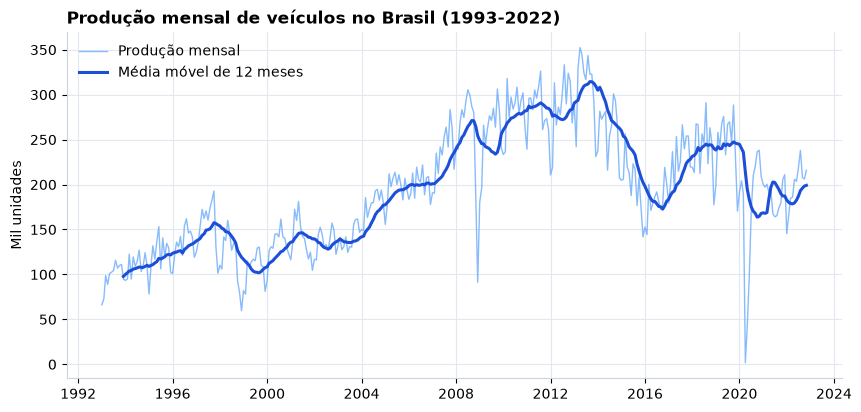

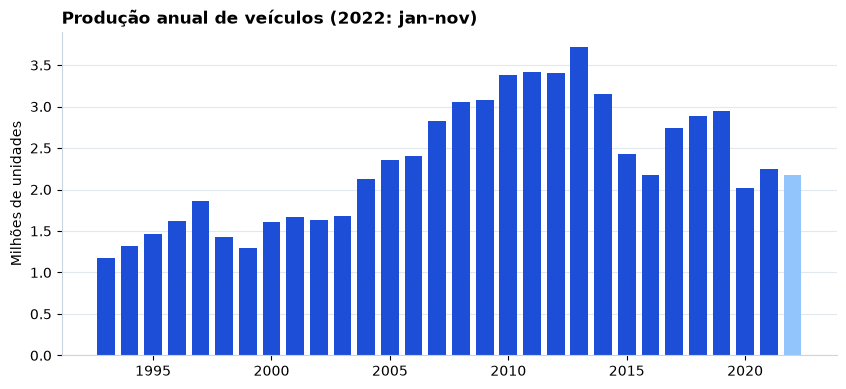

In [7]:
analise.fig_serie(df); plt.show()
analise.fig_anual(df); plt.show()

In [8]:
anual = analise.totais_anuais(df)
anual.assign(var_pct=anual["var_pct"].round(1)).set_index("ano").T

ano,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
total,1173300,1321691,1459676,1623135,1861201,1429860,1289977,1605848,1674522,1633790,...,3713813,3151831,2428089,2176784,2737256,2881017,2944988,2014055,2248253,2178202
meses,12,12,12,12,12,12,12,12,12,12,...,12,12,12,12,12,12,12,12,12,11
completo,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,False
var_pct,NaN,12.60,10.40,11.20,14.70,-23.20,-9.80,24.50,4.30,-2.40,...,9.10,-15.10,-23.00,-10.30,25.70,5.30,2.20,-31.60,11.60,NaN


## 3. RQ2 - Sazonalidade

A razão entre a produção e a média móvel centrada 2x12 isola o componente sazonal + irregular. O índice sazonal é a mediana dessa razão por mês, normalizada para média 100.

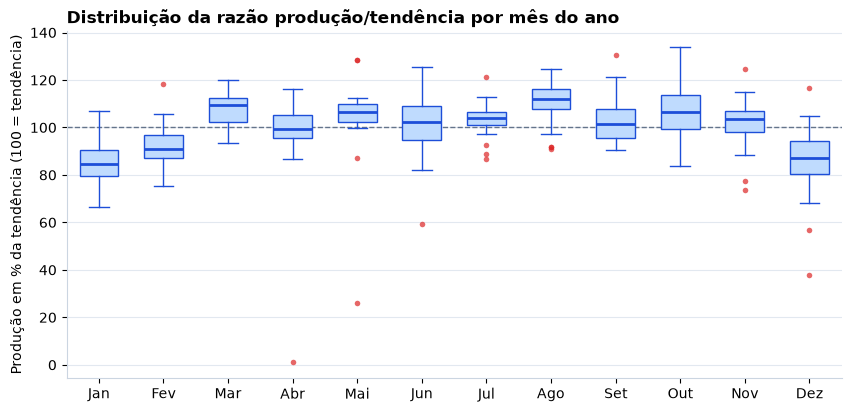

ano,1993-2002,2003-2012,2013-2022,1993-2022
mes,,,,
Jan,79.00,87.40,86.50,84.20
Fev,90.10,90.20,91.60,90.10
Mar,110.00,108.00,106.50,108.60
Abr,104.40,96.90,99.00,98.60
Mai,109.50,105.60,102.30,105.90
Jun,108.80,102.10,93.80,101.60
Jul,104.00,103.80,102.00,103.20
Ago,114.60,108.60,110.40,111.30
Set,102.50,98.80,101.80,100.80


In [9]:
analise.fig_boxplot_mensal(df); plt.show()
analise.sazonalidade_por_periodo(df).rename(index=lambda i: analise.MESES[i - 1])

In [10]:
s = m["sazonalidade"]
print(f"Amplitude do índice: {s['amplitude_pontos']} pontos")
print(f"Kruskal-Wallis: H = {s['kruskal_h']}, p = {s['kruskal_p']:.2e}")
print(f"Variância da razão explicada pelo mês (eta²): {s['eta2_pct']}%")

Amplitude do índice: 27.1 pontos
Kruskal-Wallis: H = 138.7, p = 2.95e-24
Variância da razão explicada pelo mês (eta²): 30.7%


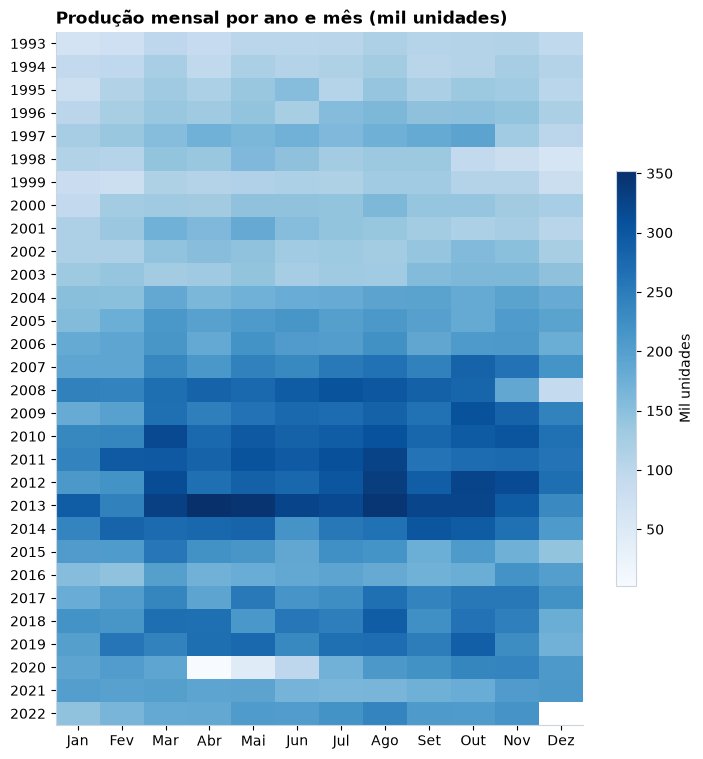

In [11]:
analise.fig_heatmap(df); plt.show()

## 4. RQ3 - Choques, quedas e outliers

In [12]:
analise.episodios_de_queda(df)

,pico,pico_valor,vale,vale_valor,queda_pct,meses_ate_vale,recuperacao,meses_ate_recuperar
0,1997-10,1890462,1999-09,1222254,-35.30,23,2004-07,81.00
1,2008-09,3254922,2009-09,2805469,-13.80,12,2010-05,20.00
2,2013-09,3774045,2020-10,1964518,-47.90,85,NaN,NaN


In [13]:
pd.DataFrame(m["choques"]).set_index("choque").T

choque,Crise financeira global (2008),Pandemia de COVID-19 (2020)
referencia_dessaz,283138,216940
fundo,2008-12,2020-04
producao_no_fundo,91314,1847
queda_dessaz_pct,-62.80,-99.10
var_anual_no_fundo_pct,-57.92,-99.31
retomada,2009-10,2020-09
meses_abaixo_da_referencia,12,6


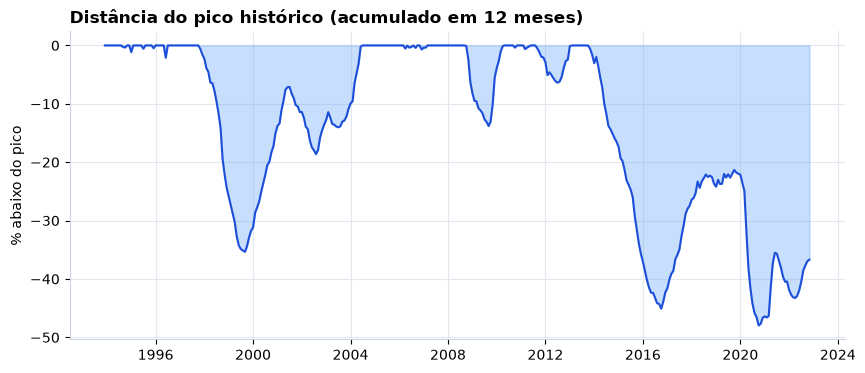

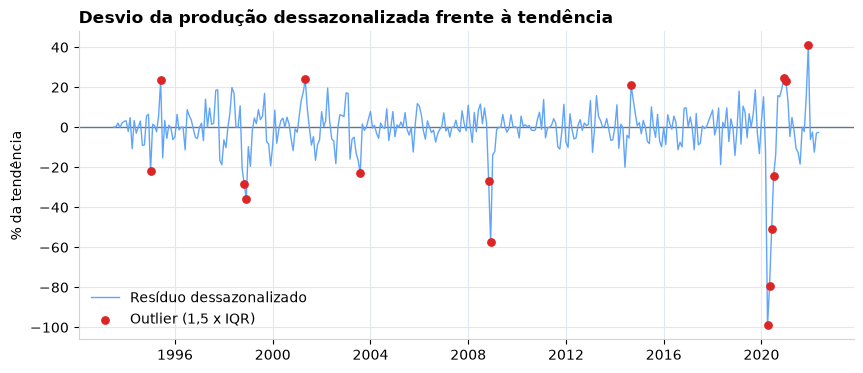

In [14]:
analise.fig_queda(df); plt.show()
analise.fig_residuos(df); plt.show()

In [15]:
df.loc[df["outlier"], ["data", "producao", "tendencia_robusta", "residuo_pct", "var_anual_pct"]]

,data,producao,tendencia_robusta,residuo_pct,var_anual_pct
24,1995-01-01,78192,"118,704.19",-21.80,-16.24
29,1995-06-01,153241,"122,217.54",23.42,40.46
70,1998-11-01,79643,"107,709.19",-28.24,-38.80
71,1998-12-01,59650,"107,709.19",-36.13,-41.09
100,2001-05-01,181201,"138,142.04",23.88,25.19
127,2003-08-01,130353,"152,182.91",-23.06,2.50
190,2008-11-01,187374,"248,128.51",-26.71,-28.68
191,2008-12-01,91314,"248,128.51",-57.55,-57.92
260,2014-09-01,300931,"246,581.82",21.05,-6.77
327,2020-04-01,1847,"196,656.19",-99.05,-99.31


## 5. Validações finais

Checagens simples que protegem a reprodutibilidade: o dado processado em disco é igual ao recalculado aqui e os totais batem com o bruto.

In [16]:
em_disco = etl.carregar_processado()
pd.testing.assert_frame_equal(em_disco, df, check_dtype=False)
assert int(df["producao"].sum()) == int(bruto["valor"].astype(int).sum())
assert df["data"].is_monotonic_increasing and df["data"].is_unique
print("Validações OK")

Validações OK
